# 과제 2 — ACT 정책 학습 및 실로봇 평가

**과제 내용**: 과제 1에서 수집한 데이터셋으로 ACT 정책을 학습하고, 실제 로봇에서 10회 평가해 성공률을 측정한 뒤, 학습된 정책을 Huggingface Hub에 업로드한다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1과 같은 저장소, assignments 폴더)에 `assignment_2.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`를 추가할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [1]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136029"
NAME = "김용현"
HF_USER = "alohateam1423"

TASK = "Grab the black cube"   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick-cube_20261008_100512"        # 과제 1 학습 데이터셋 -> 데이터셋은 바꿔도 됨.
POLICY_REPO   = f"{HF_USER}/act_pick_cube"       # 업로드한 ACT 정책
EVAL_DATASET  = f"{HF_USER}/rollout_pick-cube_20261022_102809"  # 실제 평가 녹화 데이터셋
WANDB_URL     = "https://forge.coreweave.com/wandb/launcher1423-/lerobot/runs/4m1utx7y"                               # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("정책 모델     :", f"https://huggingface.co/{POLICY_REPO}")
print("평가 데이터셋 :", f"https://huggingface.co/datasets/{EVAL_DATASET}")
print("wandb         :", WANDB_URL or "사용함: lerobot / run 4m1utx7y (URL 확인 중)")

학번/이름     : 2021136029 김용현
태스크        : Grab the black cube
학습 데이터셋 : https://huggingface.co/datasets/alohateam1423/pick-cube_20261008_100512
정책 모델     : https://huggingface.co/alohateam1423/act_pick_cube
평가 데이터셋 : https://huggingface.co/datasets/alohateam1423/rollout_pick-cube_20261022_102809
wandb         : https://forge.coreweave.com/wandb/launcher1423-/lerobot/runs/4m1utx7y


→ 과제 1의 데이터셋을 반드시 사용하지 않아도 됨.

In [2]:
# Hub 접근 확인 — 세 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (POLICY_REPO, "model"), (EVAL_DATASET, "dataset")]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\tmp\assignment-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK   [dataset] alohateam1423/pick-cube_20261008_100512  (파일 10개)


OK   [model  ] alohateam1423/act_pick_cube  (파일 9개)


OK   [dataset] alohateam1423/rollout_pick-cube_20261022_102809  (파일 9개)


## 1. 학습 설정

### 1-1. 실행한 학습 명령어
USB에 저장한 명령어이며 W&B 실행 기록에서도 동일한 인자를 확인했다. HF_USER는 alohateam1423이다.

```bash
lerobot-train \
  --dataset.repo_id=${HF_USER}/pick-cube_20261008_100512 \
  --policy.type=act \
  --policy.device=cuda \
  --policy.repo_id=${HF_USER}/act_pick_cube \
  --output_dir=outputs/train/act_pick_cube \
  --job_name=act_pick_cube \
  --batch_size=8 \
  --steps=100000 \
  --wandb.enable=true
```

### 1-2. 학습 환경
학교 GPU 지원 서비스(NVIDIA H200, 0.5 fGPU)를 이용했으며, 배치 크기 8로 100,000 step 학습에 약 2시간 43분이 소요되었다.

- 명령어에서 지정한 하이퍼파라미터: batch_size=8, steps=100000. 수업에서 사용한 명령의 값을 적용했다. 별도의 하이퍼파라미터 비교 실험은 수행하지 않았다.
- 업로드된 설정: AdamW, 학습률 0.00001, seed=1000, chunk_size=100, n_action_steps=100, ResNet18, 이미지 증강 비활성화.
- LeRobot 버전: 모델 카드 기준 0.6.0.
- W&B 사용: project=lerobot, run_id=4m1utx7y. [실행 기록](https://forge.coreweave.com/wandb/launcher1423-/lerobot/runs/4m1utx7y).

출처: [모델 카드](https://huggingface.co/alohateam1423/act_pick_cube), [학습 설정](https://huggingface.co/alohateam1423/act_pick_cube/blob/main/train_config.json).


In [3]:
# 업로드된 정책의 설정 확인
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

policy_cfg = load_json(POLICY_REPO, "config.json")
if policy_cfg:
    print("== 정책 설정 (config.json) ==")
    for k in ["type", "chunk_size", "n_action_steps", "n_obs_steps",
              "vision_backbone", "dim_model", "use_vae", "kl_weight", "optimizer_lr"]:
        if k in policy_cfg:
            print(f"{k:16}: {policy_cfg[k]}")

train_cfg = load_json(POLICY_REPO, "train_config.json")
if train_cfg:
    print("\n== 학습 설정 (train_config.json) ==")
    print("dataset   :", train_cfg.get("dataset", {}).get("repo_id"))
    for k in ["steps", "batch_size", "seed"]:
        if k in train_cfg:
            print(f"{k:10}: {train_cfg[k]}")

== 정책 설정 (config.json) ==
type            : act
chunk_size      : 100
n_action_steps  : 100
n_obs_steps     : 1
vision_backbone : resnet18
dim_model       : 512
use_vae         : True
kl_weight       : 10.0
optimizer_lr    : 1e-05



== 학습 설정 (train_config.json) ==
dataset   : alohateam1423/pick-cube_20261008_100512
steps     : 100000
batch_size: 8
seed      : 1000


### 1-3. 학습 곡선
W&B 실행 `4m1utx7y`의 실제 train/loss 화면을 캡처했다. 초기 loss가 빠르게 감소한 뒤 완만하게 낮아졌고, 100,000 step의 최종 기록은 약 0.0320이었다. 이는 학습 데이터의 loss이며 검증 loss나 실제 로봇 성공률과 동일한 지표는 아니다.

![loss curve](images/loss_curve.png)

[W&B 학습 실행](https://forge.coreweave.com/wandb/launcher1423-/lerobot/runs/4m1utx7y)


In [4]:
# (선택) wandb에서 loss를 CSV로 내보낸 경우 직접 그리기
# CSV에 step 열과 loss 열이 있다고 가정 — 열 이름은 본인 파일에 맞게 수정
import os
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "images/loss.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 대신 위 마크다운에 실제 W&B loss 그래프 캡처 첨부")

CSV 대신 위 마크다운에 실제 W&B loss 그래프 캡처 첨부


## 2. 실로봇 평가 (10회)

**평가 횟수 변경:** 교수님이 10회를 모두 수행하지 않아도 된다고 안내하여, 최신 60초 연속 녹화를 사용했다. 실제 저장 길이는 1,782프레임 / 30 FPS = 59.4초이며 저장된 에피소드는 1개이다. 이 안의 반복 시도를 시간 구간으로 구분했다. 10개의 독립 에피소드로 평가한 것은 아니다.

### 2-1. 평가 명령어
수업 양식의 lerobot-record 대신 실제 사용한 lerobot-rollout 명령을 기재한다. 아래는 USB에 저장되어 있던 명령이다.

```bash
CAMS='{ overhead: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 25}, wrist: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 25}}'
lerobot-rollout \
  --strategy.type=sentry \
  --strategy.upload_every_n_episode=5 \
  --policy.path=${HF_USER}/act_pick_cube \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="$CAMS" \
  --display_data=false \
  --dataset.repo_id=${HF_USER}/rollout_pick-cube \
  --dataset.single_task="Grab the black cube" \
  --duration=60
```

저장된 명령의 `upload_every_n_episode`는 설치 버전에 따라 옵션 철자 확인이 필요하며, 명령 파일만으로 성공 실행 당시의 모든 인자를 확정하지 않았다. 평가 데이터셋은 실제 생성된 `rollout_pick-cube_20261022_102809`를 사용했다. 카메라 요청 FPS는 25지만 저장된 데이터셋의 FPS는 30이다.


In [5]:
# 평가 데이터셋 메타데이터 확인 — 연속 녹화 1개와 내부 시도를 구분한다
info = load_json(EVAL_DATASET, "meta/info.json", repo_type="dataset")
if info:
    n_ep = info.get("total_episodes")
    print("평가 에피소드 수:", n_ep)
    print("총 프레임 수    :", info.get("total_frames"))
    print("fps             :", info.get("fps"))
    print("카메라          :", [k for k in info.get("features", {}) if k.startswith("observation.images")])
    print("\n에피소드 수 확인:", "연속 녹화 1개 확인" if n_ep == 1 else f"확인 필요 ({n_ep}개)")

평가 에피소드 수: 1
총 프레임 수    : 1782
fps             : 30
카메라          : ['observation.images.overhead', 'observation.images.wrist']

에피소드 수 확인: 연속 녹화 1개 확인


### 2-2. 회차별 결과
`[작성]` 아래 코드 셀의 `results`를 실제 결과로 채운다. 실패한 경우 원인을 구체적으로 적는다.
(예: "큐브 위치를 놓침", "잡았으나 이동 중 떨어뜨림", "상자 가장자리에 걸림")

성공 기준은 물체를 팔로워 암 기준 좌측에서 우측으로 옮겨 내려놓는 것이다. overhead와 wrist 영상의 완료 구간 5개를 수동 판독했다. 표의 episode는 모두 실제 저장 에피소드 번호 0이며 attempt가 반복 시도 번호이다. 시간은 영상 기준 근사값이다.

약 51~59.4초의 마지막 구간은 시작 위치에 물체가 없는 상태로 로봇이 움직였고, 약 56초에 사람이 물체를 다시 배치한 뒤 녹화가 종료되었다. 초기 조건과 완료 여부를 동일하게 평가할 수 없어 성공률 분모에서 제외했다. 따라서 아래 수치는 완료 구간에 한정한 기술 통계이며, 독립적인 전체 성공률이나 일반화 성능을 의미하지 않는다.


In [6]:
results = [
    # episode: 저장 에피소드, attempt: 영상 내 시도, success: 영상 판독 결과
    {"episode": 0, "attempt": 1, "time_s": "0–10", "success": True, "note": "약 9.5초 우측에 내려놓은 물체 확인"},
    {"episode": 0, "attempt": 2, "time_s": "12–20", "success": True, "note": "약 19.5초 우측에 내려놓은 물체 확인"},
    {"episode": 0, "attempt": 3, "time_s": "22–30", "success": True, "note": "약 29.5초 우측에 내려놓은 물체 확인"},
    {"episode": 0, "attempt": 4, "time_s": "32–40", "success": True, "note": "약 39.5초 우측에 내려놓은 물체 확인"},
    {"episode": 0, "attempt": 5, "time_s": "42–50", "success": True, "note": "약 49.5초 우측에 내려놓은 물체 확인"},
]

res_df = pd.DataFrame(results)
n_success = int(res_df["success"].sum())
print(f"완료 구간 기준 성공률: {n_success}/{len(res_df)} = {n_success/len(res_df)*100:.0f}%")
print("저장 에피소드 1개 내부의 반복 시도. 마지막 불완전 구간은 제외.")
res_df


완료 구간 기준 성공률: 5/5 = 100%
저장 에피소드 1개 내부의 반복 시도. 마지막 불완전 구간은 제외.


,episode,attempt,time_s,success,note
0,0,1,0–10,True,약 9.5초 우측에 내려놓은 물체 확인
1,0,2,12–20,True,약 19.5초 우측에 내려놓은 물체 확인
2,0,3,22–30,True,약 29.5초 우측에 내려놓은 물체 확인
3,0,4,32–40,True,약 39.5초 우측에 내려놓은 물체 확인
4,0,5,42–50,True,약 49.5초 우측에 내려놓은 물체 확인


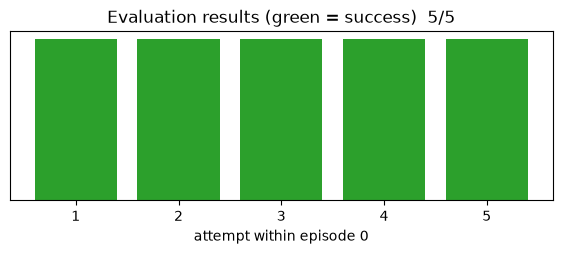

In [7]:
# 회차별 결과 시각화
colors = ["tab:green" if s else "tab:red" for s in res_df["success"]]
plt.figure(figsize=(7, 2.2))
plt.bar(res_df["attempt"].astype(str), [1]*len(res_df), color=colors)
plt.yticks([]); plt.xlabel("attempt within episode 0")
plt.title(f"Evaluation results (green = success)  {n_success}/{len(res_df)}")
plt.show()

### 2-3. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
대표 성공 장면과 실패 장면을 GIF로 만들어 `images/`에 올리고 아래에 삽입한다.

![success](images/success.gif)
![incomplete segment, excluded from scoring](images/incomplete.gif)

[최신 평가 데이터셋](https://huggingface.co/datasets/alohateam1423/rollout_pick-cube_20261022_102809) · [웹 뷰어](https://huggingface.co/spaces/lerobot/visualize_dataset?path=alohateam1423/rollout_pick-cube_20261022_102809)

첫 번째 완료 구간을 성공 GIF로 첨부했다. 완료된 5개 구간에서 명확한 실패를 확인하지 못하여 실패 GIF 대신 마지막 불완전 구간을 첨부했다. 이 구간은 실패로 집계하지 않았다. 영상은 다운로드하여 두 카메라를 함께 확인했다.


## 3. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다.

**3-1. 실패 원인 분석** — 실패한 회차들에 공통된 패턴이 있었는가? 정책의 어떤 한계 때문이라고 생각하는가?

완료된 5개 구간에서는 우측에 물체를 내려놓는 동작을 확인하여 공통적인 실패 패턴을 특정하기 어려웠다. 다만 마지막 구간에서 물체가 시작 위치에 없는데도 로봇이 기존과 비슷한 동작을 이어 갔다. 이는 물체 위치 변화나 재배치 지연에 대한 대응이 충분하지 않을 가능성을 보여 주지만, 초기 조건이 다른 불완전 구간이므로 정책 실패로 단정하지 않았다. 더 많은 독립 시도로 실패 유형을 확인할 필요가 있다.

**3-2. 데이터와 성능의 관계** — 과제 1에서 수집한 시연의 품질(일관성, 물체 위치 다양성 등)이 결과에 어떤 영향을 주었다고 보는가?

시연을 수집할 때 단봉 분포에 가까운 일관된 궤적을 만들려고 노력했으나, 매번 같은 동작을 수행하기는 어려웠다. 시작과 도착 위치가 비슷한 데이터로 학습했기 때문에 이번처럼 유사한 배치에서는 반복 동작이 가능했던 것으로 보인다. 반면 물체 위치의 다양성이 적어 새로운 위치나 배경에서도 같은 성능을 보일지는 확인하지 못했다. 시연의 일관성과 배경 변화가 정책에 미치는 영향은 별도의 조건별 평가가 필요하다.

**3-3. 개선 아이디어** — 성공률을 높이기 위해 데이터 수집, 학습 설정, 평가 환경 중 무엇을 어떻게 바꿔 보겠는가?

먼저 물체의 시작 위치와 자세를 일정한 범위 안에서 바꾸어 시연을 추가하고, 집기와 내려놓기 동작의 일관성을 높이겠다. 배경이나 조명 변화에 대해서도 데이터를 추가하거나 이미지 증강을 적용하여 효과를 비교하겠다. 학습 설정 변경은 W&B loss 곡선과 실제 로봇 성능을 함께 확인하면서 진행하겠다. 평가에서는 물체 재배치와 로봇 초기 자세 복귀를 완료한 후 각 시도를 시작하고, 실패와 중도 종료도 별도로 기록하겠다.


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [8]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        return fname in api.list_repo_files(rid, repo_type=rtype)
    except Exception:
        return False

check_items = {
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "정책 모델 업로드됨 (config.json)": file_ok(POLICY_REPO, "config.json", "model"),
    "정책 가중치 업로드됨 (model.safetensors)": file_ok(POLICY_REPO, "model.safetensors", "model"),
    "연속 평가 에피소드 1개 확인": bool(info) and info.get("total_episodes") == 1,
    "완료 시도 5개 입력 (10회 면제 안내)": len(results) == 5,
    "학습 곡선 첨부": os.path.exists("images/loss_curve.png") or os.path.exists(CSV_PATH),
    "학습 환경 및 실행 시간 출처 기재": bool(WANDB_URL),
    "실패 회차에 원인 기재": all(r["note"].strip() for r in results if not r["success"]),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] 학습 데이터셋 접근 가능 (public)
[통과] 정책 모델 업로드됨 (config.json)
[통과] 정책 가중치 업로드됨 (model.safetensors)
[통과] 연속 평가 에피소드 1개 확인
[통과] 완료 시도 5개 입력 (10회 면제 안내)
[통과] 학습 곡선 첨부
[통과] 학습 환경 및 실행 시간 출처 기재
[통과] 실패 회차에 원인 기재

모두 통과
